# Survival Analysis

## The problem
**Bodega Mensual** is a wine subscription in Mexico: every month it ships a box of imported wine to the customer's home, with two plans, *Basic* (house selection) and *Premium* (curated selection). Management is worried about **churn**: customers who cancel. The retention team has a limited budget and wants to answer:

1. **How long do customers stay?** (median lifetime, and the share still subscribed at 6 and 12 months)
2. **Do Premium customers stay longer than Basic ones?**
3. **Which factors raise or lower the risk of cancelling?** (plan, monthly fee, support tickets, age, box style)

The knowledge of *when* customers cancel tells the team *when* to launch a retention offer (for example, a free bottle), not only how many will leave.

## The data:
800 customers who signed up between Jan 2024 and Sep 2025, observed until **2025-12-31**.

| Column | Meaning |
|---|---|
| `customer_id` | Customer identifier |
| `signup_date` | Date the subscription started (the clock starts here) |
| `cancel_date` | Date of cancellation. **Empty = still active** (censored) |
| `plan` | Basic or Premium |
| `monthly_fee` | Monthly fee in MXN |
| `support_tickets` | Number of support tickets opened (late or damaged deliveries, billing questions) |
| `age` | Customer age in years |
| `wine_style` | Box style chosen **at signup**: Red, White or Mixed (reds and whites) |

In [27]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg

## 1. Build `time` and `event`
Every survival model needs **two columns per customer**:

| Column | Question it answers | Cancelled customer | Active customer (censored) |
|---|---|---|---|
| `time_months` | How long was the customer observed? | signup → cancel date | signup → **cut-off** (2025-12-31) |
| `event` | Did we actually see the cancellation? | **1** | **0** |

Active customers are **not** missing data: we know they lasted *at least* until the cut-off, and `event = 0` tells the model exactly that.

The cut-off (`CUTOFF = 2025-12-31`) is the day we extracted the data: the "today" of the analysis, the same for every customer. A customer who cancelled on or before it has `event = 1`; one who had not cancelled yet only tells us they lasted *at least* until that date, so `event = 0` (censored).

In [28]:
df = pd.read_excel("subscription_survival.xlsx", parse_dates=["signup_date", "cancel_date"])
CUTOFF = pd.Timestamp("2025-12-31")
df.head()

,customer_id,signup_date,cancel_date,plan,monthly_fee,support_tickets,age,wine_style
0,C0001,2025-06-28,2025-10-05,Premium,270,1,51,Mixed
1,C0002,2024-04-24,2024-12-20,Premium,270,3,42,Mixed
2,C0003,2024-01-17,2024-03-31,Basic,240,1,18,White
3,C0004,2025-02-12,NaT,Premium,280,1,48,Mixed
4,C0005,2024-08-21,2025-01-17,Premium,320,3,43,Red


**`event`**: did we actually see the customer cancel? 1 = yes (cancelled), 0 = no (still active, censored). This flag tells the survival methods which rows are real cancellations and which only mean "lasted at least this long".

In [29]:
df["event"] = df["cancel_date"].notna().astype(int)
df["event"].unique()

array([1, 0])

**`time_months`**: how long we observed each customer, in months. A customer who cancelled is observed until the cancellation; an active customer is observed until the cut-off, as far as we can see. Months = days ÷ 30.44, the average number of days in a month (365.25 ÷ 12).

In [30]:
df["time_months"] = (df["cancel_date"].fillna(CUTOFF) - df["signup_date"]).dt.days / 30.44

**Dummy variables**: the Cox model needs numbers, not text, so `plan` and `wine_style` become 0/1 columns. We drop one category of each, the **reference group** (Basic and Red): every coefficient compares a category with its reference.

In [31]:
dummies = pd.get_dummies(df[["plan", "wine_style"]], dtype=int)
dummies = dummies.drop(columns=["plan_Basic", "wine_style_Red"])   # references: Basic, Red
df = df.join(dummies)
df.head()

,customer_id,signup_date,cancel_date,plan,monthly_fee,support_tickets,age,wine_style,event,time_months,plan_Premium,wine_style_Mixed,wine_style_White
0,C0001,2025-06-28,2025-10-05,Premium,270,1,51,Mixed,1,3.252300,1,1,0
1,C0002,2024-04-24,2024-12-20,Premium,270,3,42,Mixed,1,7.884363,1,1,0
2,C0003,2024-01-17,2024-03-31,Basic,240,1,18,White,1,2.431012,0,0,1
3,C0004,2025-02-12,NaT,Premium,280,1,48,Mixed,0,10.578187,1,1,0
4,C0005,2024-08-21,2025-01-17,Premium,320,3,43,Red,1,4.894875,1,0,0


**Check:** three cancelled and three active customers side by side. Active ones have no cancel date (`NaT`) and `event = 0`.

In [32]:
cols = ["customer_id", "signup_date", "cancel_date", "event", "time_months"]
display(df[df["event"] == 1][cols].head(3))
display(df[df["event"] == 0][cols].head(3))

,customer_id,signup_date,cancel_date,event,time_months
0,C0001,2025-06-28,2025-10-05,1,3.252300
1,C0002,2024-04-24,2024-12-20,1,7.884363
2,C0003,2024-01-17,2024-03-31,1,2.431012


,customer_id,signup_date,cancel_date,event,time_months
3,C0004,2025-02-12,NaT,0,10.578187
7,C0008,2024-08-24,NaT,0,16.228647
8,C0009,2025-02-15,NaT,0,10.479632


## 2. Explore the data
Before modeling, check the data and describe the customers and the censoring.

**Quality checks**

In [33]:
print(df[["signup_date", "plan", "monthly_fee", "support_tickets", "age", "wine_style"]].isna().sum().sum(), "missing values (excluding cancel_date)")
print("Duplicated customers:", df["customer_id"].duplicated().sum())
print("Cancel before signup:", (df["cancel_date"] < df["signup_date"]).sum())
print("Signups after cut-off:", (df["signup_date"] > CUTOFF).sum())
print("Customers with time <= 0:", (df["time_months"] <= 0).sum())

0 missing values (excluding cancel_date)
Duplicated customers: 0
Cancel before signup: 0
Signups after cut-off: 0
Customers with time <= 0: 0


Fee, tickets and age have reasonable ranges, with no extreme outliers. The median of `time_months` (6.6) is **not** the median lifetime: it mixes real cancellations with the times of customers who have not left yet. That is what Kaplan–Meier fixes.

In [34]:
df[["time_months", "monthly_fee", "support_tickets", "age"]].describe().round(1)

,time_months,monthly_fee,support_tickets,age
count,800.0,800.0,800.0,800.0
mean,8.1,263.1,1.5,38.4
std,5.5,61.4,1.2,9.6
min,0.0,120.0,0.0,18.0
25%,3.8,220.0,1.0,32.0
50%,6.6,260.0,1.0,38.0
75%,11.4,310.0,2.0,45.0
max,23.9,420.0,6.0,69.0


Fee and age are roughly bell-shaped (mean ≈ median). Support tickets are concentrated at 0–2, with only a few customers at 4 or more.

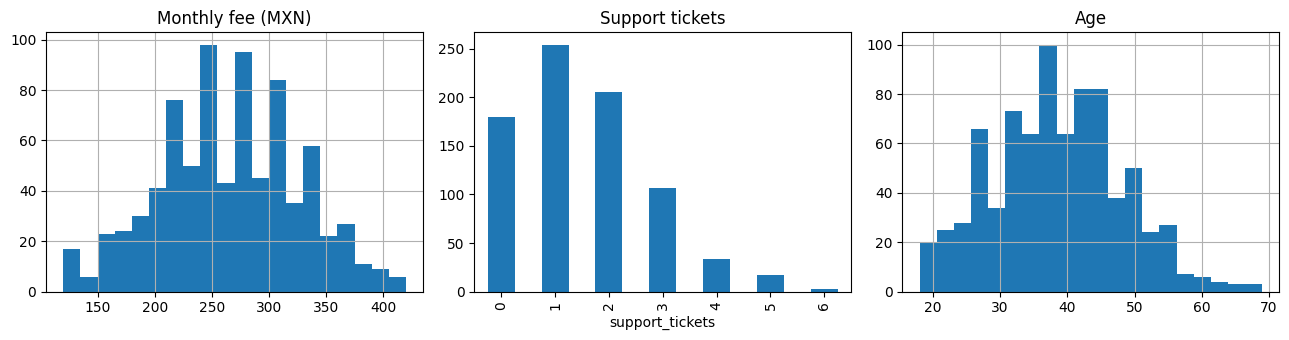

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
df["monthly_fee"].hist(ax=ax[0], bins=20); ax[0].set_title("Monthly fee (MXN)")
df["support_tickets"].value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Support tickets")
df["age"].hist(ax=ax[2], bins=20); ax[2].set_title("Age")
plt.tight_layout(); plt.show()

**Customer mix and plan comparison**

About 68% of customers are Basic and 32% Premium; by box style, 40% Red, 33% Mixed and 26% White. Premium customers pay more (≈ 295 vs 248 MXN), while tickets and age are similar between plans.

In [36]:
print(df["plan"].value_counts(normalize=True).round(2).to_dict())
print(df["wine_style"].value_counts(normalize=True).round(2).to_dict())
df.groupby("plan").agg(n=("event", "size"), pct_censored=("event", lambda x: 1 - x.mean()),
                       fee=("monthly_fee", "mean"), tickets=("support_tickets", "mean"),
                       age=("age", "mean")).round(2)

{'Basic': 0.68, 'Premium': 0.32}
{'Red': 0.4, 'Mixed': 0.33, 'White': 0.26}


,n,pct_censored,fee,tickets,age
plan,,,,,
Basic,546,0.36,248.24,1.5,38.28
Premium,254,0.48,294.96,1.6,38.77


In [37]:
df.groupby("wine_style").agg(n=("event", "size"), pct_censored=("event", lambda x: 1 - x.mean()),
                       fee=("monthly_fee", "mean"), tickets=("support_tickets", "mean"),
                       age=("age", "mean")).round(2)

,n,pct_censored,fee,tickets,age
wine_style,,,,,
Mixed,266,0.44,262.97,1.47,38.95
Red,324,0.38,264.63,1.54,37.90
White,210,0.38,260.81,1.58,38.60


**Censoring**: months observed, cancelled vs still active

About 40% of the customers are censored, and the share is higher in Premium (48% vs 36%): Premium customers are more often still active, a first hint that they stay longer.

Censored: 39.9%


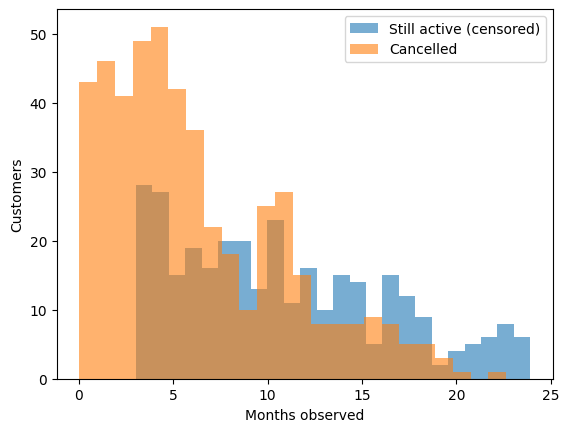

In [38]:
print("Censored: {:.1%}".format(1 - df["event"].mean()))
for ev, g in df.groupby("event"):
    plt.hist(g["time_months"], bins=24, alpha=0.6, label="Cancelled" if ev else "Still active (censored)")
plt.xlabel("Months observed"); plt.ylabel("Customers"); plt.legend(); plt.show()

## 3. Train / test split (80 / 20)
We fit on train and only touch test at the end.

In [39]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(len(train), len(test))
print("Censored (train): {:.1%}".format(1 - train["event"].mean()))
print("Censored (test): {:.1%}".format(1 - test["event"].mean()))

640 160
Censored (train): 39.1%
Censored (test): 43.1%


## 4. Kaplan–Meier (all customers)
**What is it for?** Kaplan–Meier estimates the survival curve $S(t)$: the probability that a customer is still subscribed after $t$ months. It handles censoring by using each active customer only for as long as we have observed them. Use it to describe how long customers stay (median, $S(6)$, $S(12)$) without assuming any distribution.

**Fit the curve.** `SurvfuncRight(time, event)` takes the observed time and the event flag of each customer and estimates the Kaplan–Meier curve.

In [40]:
sf = SurvfuncRight(train["time_months"], train["event"])

**What does it return?** The object stores the curve in four arrays, one value per month at which at least one customer cancelled (the table below is just to display them):
- `surv_times`: the times of the cancellations.
- `n_risk`: customers still being observed just before that time.
- `n_events`: cancellations at that time.
- `surv_prob`: the survival probability $S(t)$ after that time.

Each step multiplies the previous value by the share who did not cancel: $S(t)=S(\text{previous})\times(1-n\_events/n\_risk)$. Active customers (censored) just leave `n_risk` when their observation ends; they never count as a cancellation.

In [41]:
table = pd.DataFrame({"time": sf.surv_times, "n_risk": sf.n_risk, "n_events": sf.n_events, "S(t)": sf.surv_prob})
table.head(10)

,time,n_risk,n_events,S(t)
0,0.065703,640,1.0,0.998437
1,0.098555,639,1.0,0.996875
2,0.131406,638,2.0,0.993750
3,0.164258,636,1.0,0.992187
4,0.262812,635,1.0,0.990625
5,0.295664,634,3.0,0.985937
6,0.361367,631,2.0,0.982812
7,0.492773,629,3.0,0.978125
8,0.558476,626,1.0,0.976562
9,0.591327,625,1.0,0.975000


**Reading $S(t)$ at a given month.** The curve is a staircase: it only changes at the cancellation times, so $S(6)$ is the value of the last step at or before month 6. The function `S_at` finds that step:
- `np.searchsorted(sf.surv_times, t, side="right")` counts how many cancellation times are $\le t$.
- Subtracting 1 gives the position of the last of them.
- `sf.surv_prob[i]` is the survival probability at that step.

In [42]:
def S_at(sf, t):
    i = np.searchsorted(sf.surv_times, t, side="right") - 1
    return sf.surv_prob[i] if i >= 0 else 1.0   # before the first cancellation S = 1

**Results.** The median survival (`sf.quantile(0.5)`) is the time at which $S(t)$ drops to 0.5. We print it next to the two medians that ignore censoring to see the effect of ignoring censoring, and then $S(6)$ and $S(12)$.

In [43]:
print("Median ignoring censoring (everyone):      {:.1f}".format(train["time_months"].median()))
print("Median of cancelled customers only:        {:.1f}".format(train.loc[train["event"] == 1, "time_months"].median()))
print("Median survival: {:.1f} months".format(sf.quantile(0.5)))
print("S(6)  = {:.2f}".format(S_at(sf, 6)))
print("S(12) = {:.2f}".format(S_at(sf, 12)))

Median ignoring censoring (everyone):      6.9
Median of cancelled customers only:        5.0
Median survival: 9.9 months
S(6)  = 0.64
S(12) = 0.40


**Interpretation:**
- **Median survival (9.9 months):** half of the customers have cancelled by then.
- **$S(6)=0.64$:** after 6 months, 64% are still subscribed, so we lose about 36% of the customers in the first six months.
- **$S(12)=0.40$:** after a year, only 40% are still subscribed, so we lose 60% within the first year. The first year is where retention matters most.
- **Medians that ignore censoring (6.9 and 5.0):** both understate the lifetime. The first treats still-active customers as if they had left; the second ignores everyone who has not cancelled yet, precisely the ones who last longer.

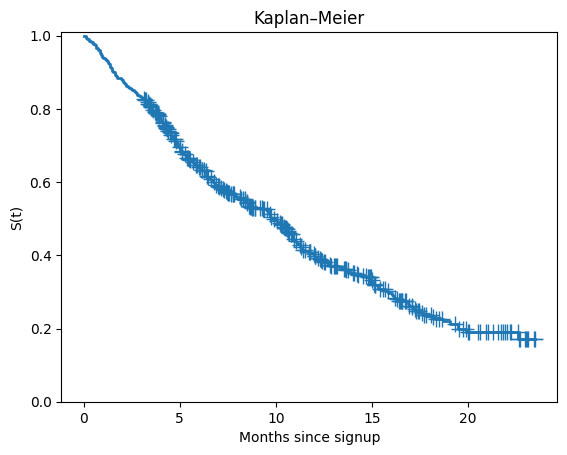

In [44]:
sf.plot(); plt.xlabel("Months since signup"); plt.ylabel("S(t)"); plt.title("Kaplan–Meier"); plt.show()

## 5. Compare groups: KM by group + log-rank test

**What is it for?** Kaplan–Meier by group lets us *see* whether groups survive differently, and the log-rank test tells us whether the difference is large enough to be considered real, or could just come from the customers in this sample. It compares whole curves, but it cannot adjust for other variables or measure the size of the effect. We do it for the two categorical variables: plan and box style.

**One curve per group.** For each categorical variable (`plan`, `wine_style`), `groupby` splits the training customers into its groups. For each group the loop fits its own Kaplan–Meier curve with `SurvfuncRight`, draws it on the same axes and prints its median and $S(12)$, read with `S_at` as before.

plan       Basic    n=435  median = 9.6 months  S(12) = 0.36
plan       Premium  n=205  median = 11.2 months  S(12) = 0.47
wine_style Mixed    n=219  median = 11.1 months  S(12) = 0.47
wine_style Red      n=253  median = 10.1 months  S(12) = 0.37
wine_style White    n=168  median = 8.4 months  S(12) = 0.36


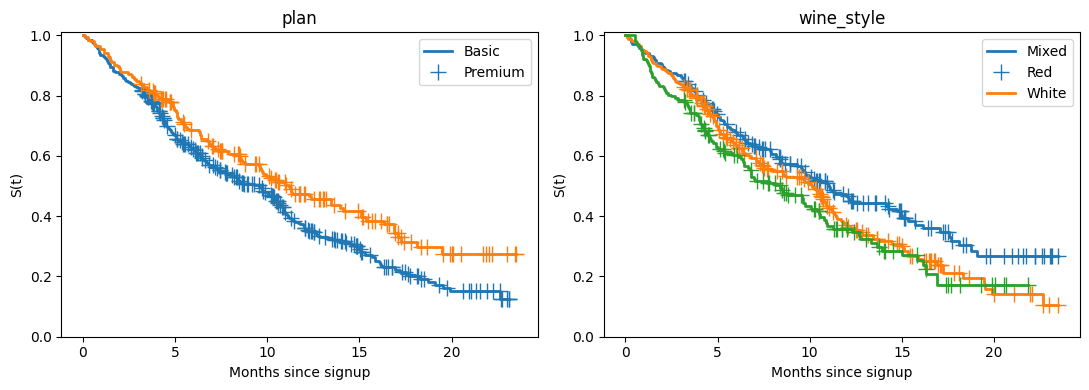

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, var in enumerate(["plan", "wine_style"]):
    names = []
    for name, g in train.groupby(var):
        s = SurvfuncRight(g["time_months"], g["event"])
        s.plot(ax[k])
        names.append(name)
        print(f"{var:10s} {name:8s} n={len(g):3d}  median = {s.quantile(0.5):.1f} months  S(12) = {S_at(s, 12):.2f}")
    ax[k].set_title(var); ax[k].set_xlabel("Months since signup"); ax[k].set_ylabel("S(t)"); ax[k].legend(names)
plt.tight_layout(); plt.show()

**Interpretation:**
- **Plan:** Premium customers last 11.2 months against 9.6 for Basic, and 47% are still subscribed at 12 months against 36%.
- **Box style:** Mixed lasts 11.1 months, Red 10.1 and White 8.4. At 12 months, 47% of Mixed, 37% of Red and 36% of White are still subscribed.
- **The curves:** Premium stays above Basic; Mixed stays above Red and White.
- **What we cannot say yet:** the plot shows differences, but they may come from the customers in this sample. The log-rank test below checks whether they are large enough to be considered real.

**Log-rank test.** `survdiff(time, event, group)` compares the curves of the groups and returns the chi-square statistic and the p-value of $H_0$: the curves are equal.

$H_0: S_{1}(t)=S_{2}(t)=\dots$ for all $t$  vs  $H_1$: at least one curve differs.

In [46]:
for var in ["plan", "wine_style"]:
    stat, pval = survdiff(train["time_months"], train["event"], train[var])
    print(f"{var:10s} Log-rank chi2 = {stat:.2f}, p-value = {pval:.4f}")

plan       Log-rank chi2 = 6.93, p-value = 0.0085
wine_style Log-rank chi2 = 7.94, p-value = 0.0189


**Interpretation:**
- **Plan (p ≈ 0.008):** below 0.05, so we reject $H_0$: Premium and Basic customers do not survive equally.
- **Box style (chi2 ≈ 7.94, p ≈ 0.019):** below 0.05, so we reject $H_0$: the three box styles do not all survive equally.
- **What the test does not tell us:**
  - For box style, it does not say *which* styles differ.
  - It does not say how large the effect is.
  - It does not adjust for other variables (Premium customers also pay more).
  - For all of this we use the Cox model.

## 6. Cox proportional hazards model
$h(t\mid x)=h_0(t)\exp(\beta_1\,premium+\beta_2\,tickets+\beta_3\,fee+\beta_4\,age+\beta_5\,mixed+\beta_6\,white)$  
`exp(coef)` is a **hazard ratio**: HR > 1 means higher cancellation risk, HR < 1 means lower.

**What is it for?** The Cox model measures how several variables at once (plan, fee, tickets, age, box style) change the risk of cancelling, adjusting for each other. It does not assume a shape for the survival curve, only that each variable multiplies the risk by a constant factor over time (proportional hazards). Use it to answer *which factors matter and by how much*.

**Fit the model.** `PHReg.from_formula` fits the Cox model: the formula has the time on the left and the variables on the right, `status` is the event flag, and `ties="breslow"` is the method used when several customers cancel at the same time (a technical detail). We first look at the summary of the model.

In [47]:
cox = PHReg.from_formula(
    "time_months ~ plan_Premium + support_tickets + monthly_fee + age + wine_style_Mixed + wine_style_White",
    data=train, status=train["event"].values, ties="breslow")
res = cox.fit()
print(res.summary())

                            Results: PHReg
Model:                      PH Reg             Sample size:        640
Dependent variable:         time_months        Num. events:        390
Ties:                       Breslow                                   
----------------------------------------------------------------------
                  log HR log HR SE   HR      t    P>|t|  [0.025 0.975]
----------------------------------------------------------------------
plan_Premium     -0.4461    0.1223 0.6401 -3.6461 0.0003 0.5037 0.8136
support_tickets   0.1158    0.0410 1.1227  2.8233 0.0048 1.0360 1.2167
monthly_fee       0.0022    0.0009 1.0022  2.4842 0.0130 1.0005 1.0040
age              -0.0077    0.0053 0.9923 -1.4549 0.1457 0.9821 1.0027
wine_style_Mixed -0.2471    0.1208 0.7810 -2.0466 0.0407 0.6164 0.9896
wine_style_White  0.1198    0.1253 1.1273  0.9568 0.3387 0.8819 1.4410
Confidence intervals are for the hazard ratios


**Reading the summary.** The summary shows, for each variable:
- **`log HR`:** its effect on the **logarithm** of the hazard (hard to read directly), with its standard error (`log HR SE`).
- **`HR`:** $\exp(\text{log HR})$, the **hazard ratio**: the factor by which the risk of cancelling is multiplied when the variable goes up by one unit.
- **`t` and `P>|t|`:** the test statistic and p-value of "the variable has no effect".

Example: `plan_Premium` has log HR $=-0.446$, so $\exp(-0.446)=0.64$.

In [48]:
hr = pd.DataFrame({"coef": res.params, "HR": np.exp(res.params), "p-value": res.pvalues},
                  index=res.model.exog_names).round(4)
hr

,coef,HR,p-value
plan_Premium,-0.4461,0.6401,0.0003
support_tickets,0.1158,1.1227,0.0048
monthly_fee,0.0022,1.0022,0.0130
age,-0.0077,0.9923,0.1457
wine_style_Mixed,-0.2471,0.7810,0.0407
wine_style_White,0.1198,1.1273,0.3387


**Interpretation:** each HR compares two customers who are the same in everything else ("holding the other variables constant"), as in multiple regression.
- **HR < 1:** lower risk of cancelling in any given month.
- **HR > 1:** higher risk of cancelling in any given month.

- **Premium vs Basic:** HR ≈ 0.64 (p < 0.001). A Premium customer has about 36% lower risk of cancelling than a Basic customer with the same fee, tickets, age and box style.
- **Support tickets:** HR ≈ 1.12 (p ≈ 0.005). With each extra ticket the risk goes up about 12%: customers with problems cancel earlier, a signal to follow up after a ticket.
- **Monthly fee:** HR ≈ 1.002 per peso (p ≈ 0.013). One peso looks tiny, but between two customers on the same plan, the one paying 100 MXN more has about 25% higher risk (1.0022¹⁰⁰ ≈ 1.25).
- **Age:** HR ≈ 0.99 (p ≈ 0.15). No evidence that age matters.
- **Mixed box vs Red:** HR ≈ 0.78 (p ≈ 0.04). About 22% lower risk, but the evidence is borderline.
- **White box vs Red:** HR ≈ 1.13 (p ≈ 0.34). No evidence of a difference.

These are associations: they do not prove that changing a variable (for example, lowering the fee) would change who cancels.

## 7. Check the proportional-hazards assumption (visual)
**What is it for?** The Cox model assumes the effect of a variable is constant over time (proportional hazards): for example, Premium has the same lower risk in month 2 as in month 12. This plot is a quick visual check of that assumption. If it holds, the curves of $\log(-\log S(t))$ of the groups of a variable are roughly **parallel**. It only works for categorical variables, so we check plan and box style; fee, tickets and age are numeric and are not shown.

**Why $\log(-\log S)$?**
- **What we want to check:** that one group's cumulative hazard $H$ (the risk accumulated up to each month) is the other's multiplied by a constant, for example $H_{Premium}(t)=0.64\times H_{Basic}(t)$.
- **Why not plot $H$ directly:** a multiplication by a constant is hard to see. The curves keep moving apart (in the example below, the gap grows from 0.11 to 0.40), and we cannot tell a constant effect from one that changes over time.
- **Why take the log:** the log turns a multiplication into a sum, $\log H_{Premium}=\log 0.64+\log H_{Basic}$, so the curves stay at the **same vertical distance**. That is what "parallel" means, and it is easy to recognise.
- **How we get $H$:** Kaplan–Meier gives us $S(t)$, not $H(t)$. They are related by $S(t)=\exp(-H(t))$, so $H(t)=-\log S(t)$. Therefore $\log H(t)=\log(-\log S(t))$.

Example with made-up numbers (HR = 0.64). For each group the transformation is applied to its own curve, and then we compare the two lines:

| Month | $H$ Basic | $H$ Premium | $\log H$ Basic | $\log H$ Premium | Difference |
|---|---|---|---|---|---|
| 3 | 0.30 | 0.19 | −1.20 | −1.65 | −0.45 |
| 6 | 0.60 | 0.38 | −0.51 | −0.96 | −0.45 |
| 12 | 1.10 | 0.70 | 0.10 | −0.35 | −0.45 |

$H$ keeps moving apart, but $\log H$ stays at the same distance ($\log 0.64\approx -0.45$). That constant distance is what we look for in the plot.

**Why $\log(\text{time})$?** It is only a scale for the horizontal axis that spreads out the early months, where most cancellations happen. The check does not depend on it.

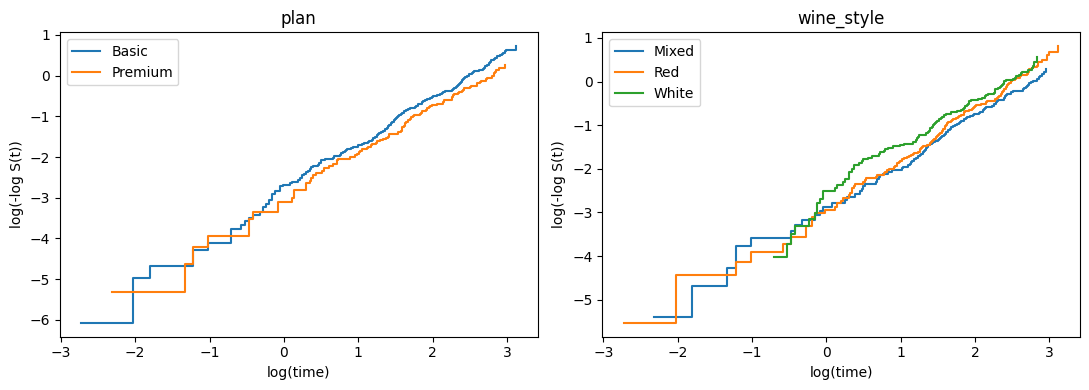

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, var in enumerate(["plan", "wine_style"]):
    for name, g in train.groupby(var):
        s = SurvfuncRight(g["time_months"], g["event"])
        m = (s.surv_prob > 0) & (s.surv_prob < 1) & (s.surv_times > 0)
        ax[k].step(np.log(s.surv_times[m]), np.log(-np.log(s.surv_prob[m])), where="post", label=name)
    ax[k].set_title(var); ax[k].set_xlabel("log(time)"); ax[k].set_ylabel("log(-log S(t))"); ax[k].legend()
plt.tight_layout(); plt.show()

**Interpretation:**
- **Plan:** the Basic and Premium lines keep a roughly constant distance, so the assumption is reasonable.
- **Box style:** Mixed stays below Red at a similar distance, while White starts above Red and gets closer later. The early part of each curve rests on few cancellations, so it is noisy.
- **Overall:** there is no strong evidence against proportional hazards.
- **What would be a problem:** if the lines of a variable crossed clearly, its effect would change over time and the Cox model would not describe it well.

## 8. Does the model separate customers by risk? (test set)
**What is it for?** The model does not predict an exact cancellation date. It gives each customer a **risk score**, and the question is whether the customers it flags as higher risk really cancel sooner, on data it has not seen.

### Risk score.
For each test customer we multiply every variable by its coefficient and add them up (the log of its relative hazard). A higher score means a higher risk of cancelling.

In [50]:
features = ["plan_Premium", "support_tickets", "monthly_fee", "age", "wine_style_Mixed", "wine_style_White"]
test["risk"] = test[features].values @ res.params
test[["plan", "monthly_fee", "support_tickets", "time_months", "event", "risk"]].head()

,plan,monthly_fee,support_tickets,time_months,event,risk
696,Basic,280,3,2.890933,1,0.311484
667,Premium,250,1,9.658344,0,-0.046593
63,Basic,310,1,5.157687,1,0.262096
533,Basic,300,1,13.173456,0,0.579653
66,Basic,220,3,8.344284,1,0.518298


### Higher-risk vs lower-risk customers.
We split the test customers at the median risk score and draw a Kaplan–Meier curve for each group, as in step 5. If the model works, the higher-risk curve should be clearly below the other. The log-rank test checks whether they differ.

Higher risk  n= 80  S(12) = 0.29
Lower risk   n= 80  S(12) = 0.47


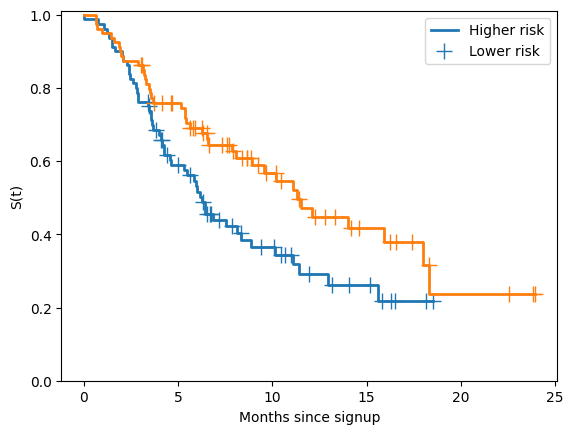

Log-rank chi2 = 5.20, p-value = 0.0226


In [51]:
test["risk_group"] = np.where(test["risk"] > test["risk"].median(), "Higher risk", "Lower risk")

fig, ax = plt.subplots()
for name, g in test.groupby("risk_group"):
    s = SurvfuncRight(g["time_months"], g["event"], title=name)
    s.plot(ax)
    print(f"{name:12s} n={len(g):3d}  S(12) = {S_at(s, 12):.2f}")
ax.set_xlabel("Months since signup"); ax.set_ylabel("S(t)"); ax.legend(["Higher risk", "Lower risk"]); plt.show()

stat, pval = survdiff(test["time_months"], test["event"], test["risk_group"])
print(f"Log-rank chi2 = {stat:.2f}, p-value = {pval:.4f}")

**Interpretation:**
- **Risk groups:** among the higher-risk half, about 29% are still subscribed at 12 months, against 47% in the lower-risk half, a difference of 18 percentage points.
- **$H_0$:** the higher-risk and lower-risk customers have the same survival curve.
- **p-value (≈ 0.02):** if the two groups really had the same survival, we would see a difference this large in only about 2% of samples.
- **Decision:** the p-value is below 0.05, so we reject $H_0$: the two groups do not survive equally.
- **Conclusion:** the model separates customers by risk, on customers it has not seen.

### C-index (one number). 
It measures how well the risk score puts customers in the right order.
- **Take two test customers** where we know who cancelled first.
- **Check the model:** did it give the higher risk score to the one who cancelled first? If yes, the pair is correct.
- **Repeat for all possible pairs** and compute the share of correct pairs. That share is the C-index.
- **How to read it:** 0.5 is a coin flip, 1 is perfect.

**Which pairs are compared?** The code goes through each customer who cancelled (`i`) and compares him or her against **all the customers observed for longer** (`later`), whether those cancelled afterwards or are still active. Customers who are still active are never `i`, because we do not know when they will cancel, but they can be the partner of someone who cancelled before. Ties in the score count as half a correct pair.

**Example with three customers:**

| Customer | What happened | Risk score |
|---|---|---|
| A | Cancelled in month 3 | 0.8 |
| B | Cancelled in month 7 | 0.2 |
| C | Still active in month 10 | 0.5 |

| Pair | Who cancelled first | Model gave the higher risk to | Result |
|---|---|---|---|
| A and B | A | A (0.8 vs 0.2) | Correct |
| A and C | A | A (0.8 vs 0.5) | Correct |
| B and C | B | C (0.5 vs 0.2) | Wrong |

C-index = 2 correct pairs out of 3 = 0.67.

In [52]:
def c_index(time, event, risk):
    num = den = 0
    for i in np.where(event == 1)[0]:
        later = time > time[i]
        den += later.sum()
        num += (risk[later] < risk[i]).sum() + 0.5 * (risk[later] == risk[i]).sum()
    return num / den

print("C-index (test): {:.3f}".format(c_index(test["time_months"].values, test["event"].values, test["risk"].values)))

C-index (test): 0.606


**Interpretation:**
- **C-index (≈ 0.61):** in 61% of the comparable pairs, the model gave the higher risk score to the customer who cancelled first. A coin flip would give 50%.
- **What this model is good for:** identifying groups of customers with higher risk and understanding which factors matter.
- **What it is not good for:** saying which individual customer will cancel. With a C-index of about 0.61, it is not precise enough for that.
- **Limit of the C-index:** it only measures the order of the risk scores, not whether the predicted probabilities are right.

## Back to the problem
1. **How long do customers stay?** Half of the customers cancel before about 10 months (median 9.9). 64% are still subscribed at 6 months and 40% at 12 months, so the first year is where we lose most customers.
2. **Do Premium customers stay longer than Basic ones?** Yes.
   - Median of 11.2 months against 9.6.
   - The log-rank test rejects equal survival (p ≈ 0.008).
3. **Which factors raise or lower the risk of cancelling?** Support tickets (+12% risk per ticket) and a higher monthly fee (about +25% per 100 MXN) raise it; the Premium plan (−36%) lowers it. The Mixed box (−22%) points the same way but with borderline evidence, and age and the White box show no clear effect.

**What the retention team can do:** launch the retention offer (for example, a free bottle) before month 6, and follow up with customers right after they open a support ticket. The model separates higher-risk from lower-risk customers (C ≈ 0.61: useful for groups, not precise for one customer), and the results are associations, so these actions are worth testing before assuming they will reduce cancellations.